In [1]:
%pip install matplotlib pandas numpy seaborn SciencePlots

Note: you may need to restart the kernel to use updated packages.


In [2]:
import matplotlib.pyplot as plt
import scienceplots
import numpy as np 
import pandas as pd
import os 

# Intensity reconstruction

In [3]:
os.listdir()
intensity_train_csv = pd.read_csv(os.path.join("analysis", "retina_train_saliency.csv"))

intensity_train_csv.columns

Index(['Step', 'FIRE_saliency_seq=50_gk5_20251201_014614 - train_loss_epoch',
       'FIRE_saliency_seq=50_gk5_20251201_014614 - train_loss_epoch__MIN',
       'FIRE_saliency_seq=50_gk5_20251201_014614 - train_loss_epoch__MAX',
       'FIREnetwork_DVS_seq=50 - train_loss_epoch',
       'FIREnetwork_DVS_seq=50 - train_loss_epoch__MIN',
       'FIREnetwork_DVS_seq=50 - train_loss_epoch__MAX',
       'FIRE_saliency_p2=1.0_20251128_082440 - train_loss_epoch',
       'FIRE_saliency_p2=1.0_20251128_082440 - train_loss_epoch__MIN',
       'FIRE_saliency_p2=1.0_20251128_082440 - train_loss_epoch__MAX',
       'FIREnetwork_DVS2_seq=30 - train_loss_epoch',
       'FIREnetwork_DVS2_seq=30 - train_loss_epoch__MIN',
       'FIREnetwork_DVS2_seq=30 - train_loss_epoch__MAX'],
      dtype='str')

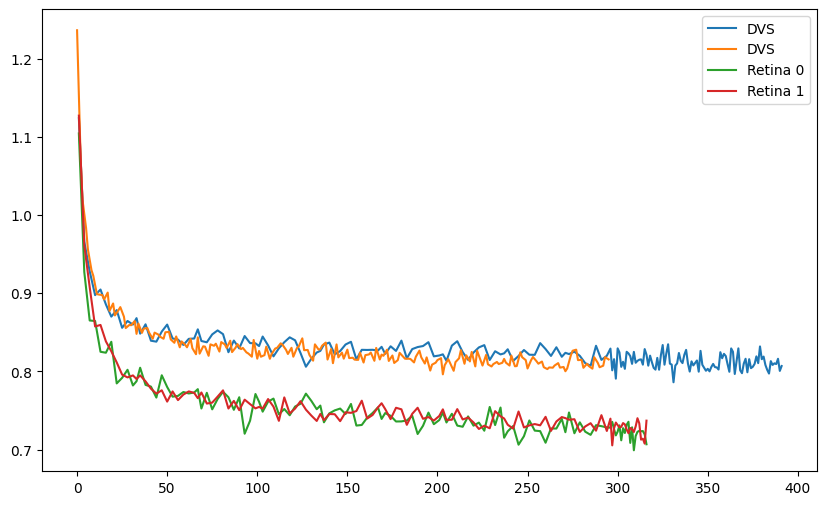

In [4]:
dvs_group_train = ['FIREnetwork_DVS2_seq=30 - train_loss_epoch',
                   'FIREnetwork_DVS_seq=50 - train_loss_epoch']

retina_group_train = ['FIRE_saliency_p2=1.0_20251128_082440 - train_loss_epoch',
                      'FIRE_saliency_seq=50_gk5_20251201_014614 - train_loss_epoch']


plt.figure(figsize=(10, 6))

for col in dvs_group_train:
    data = intensity_train_csv[col]
    plt.plot(data[data.notna()], label="DVS")

for i, col in enumerate(retina_group_train):
    data = intensity_train_csv[col]
    plt.plot(data[data.notna()], label=f"Retina {i}")

plt.legend()
plt.show()

Plot saved as saliency_training_loss.png


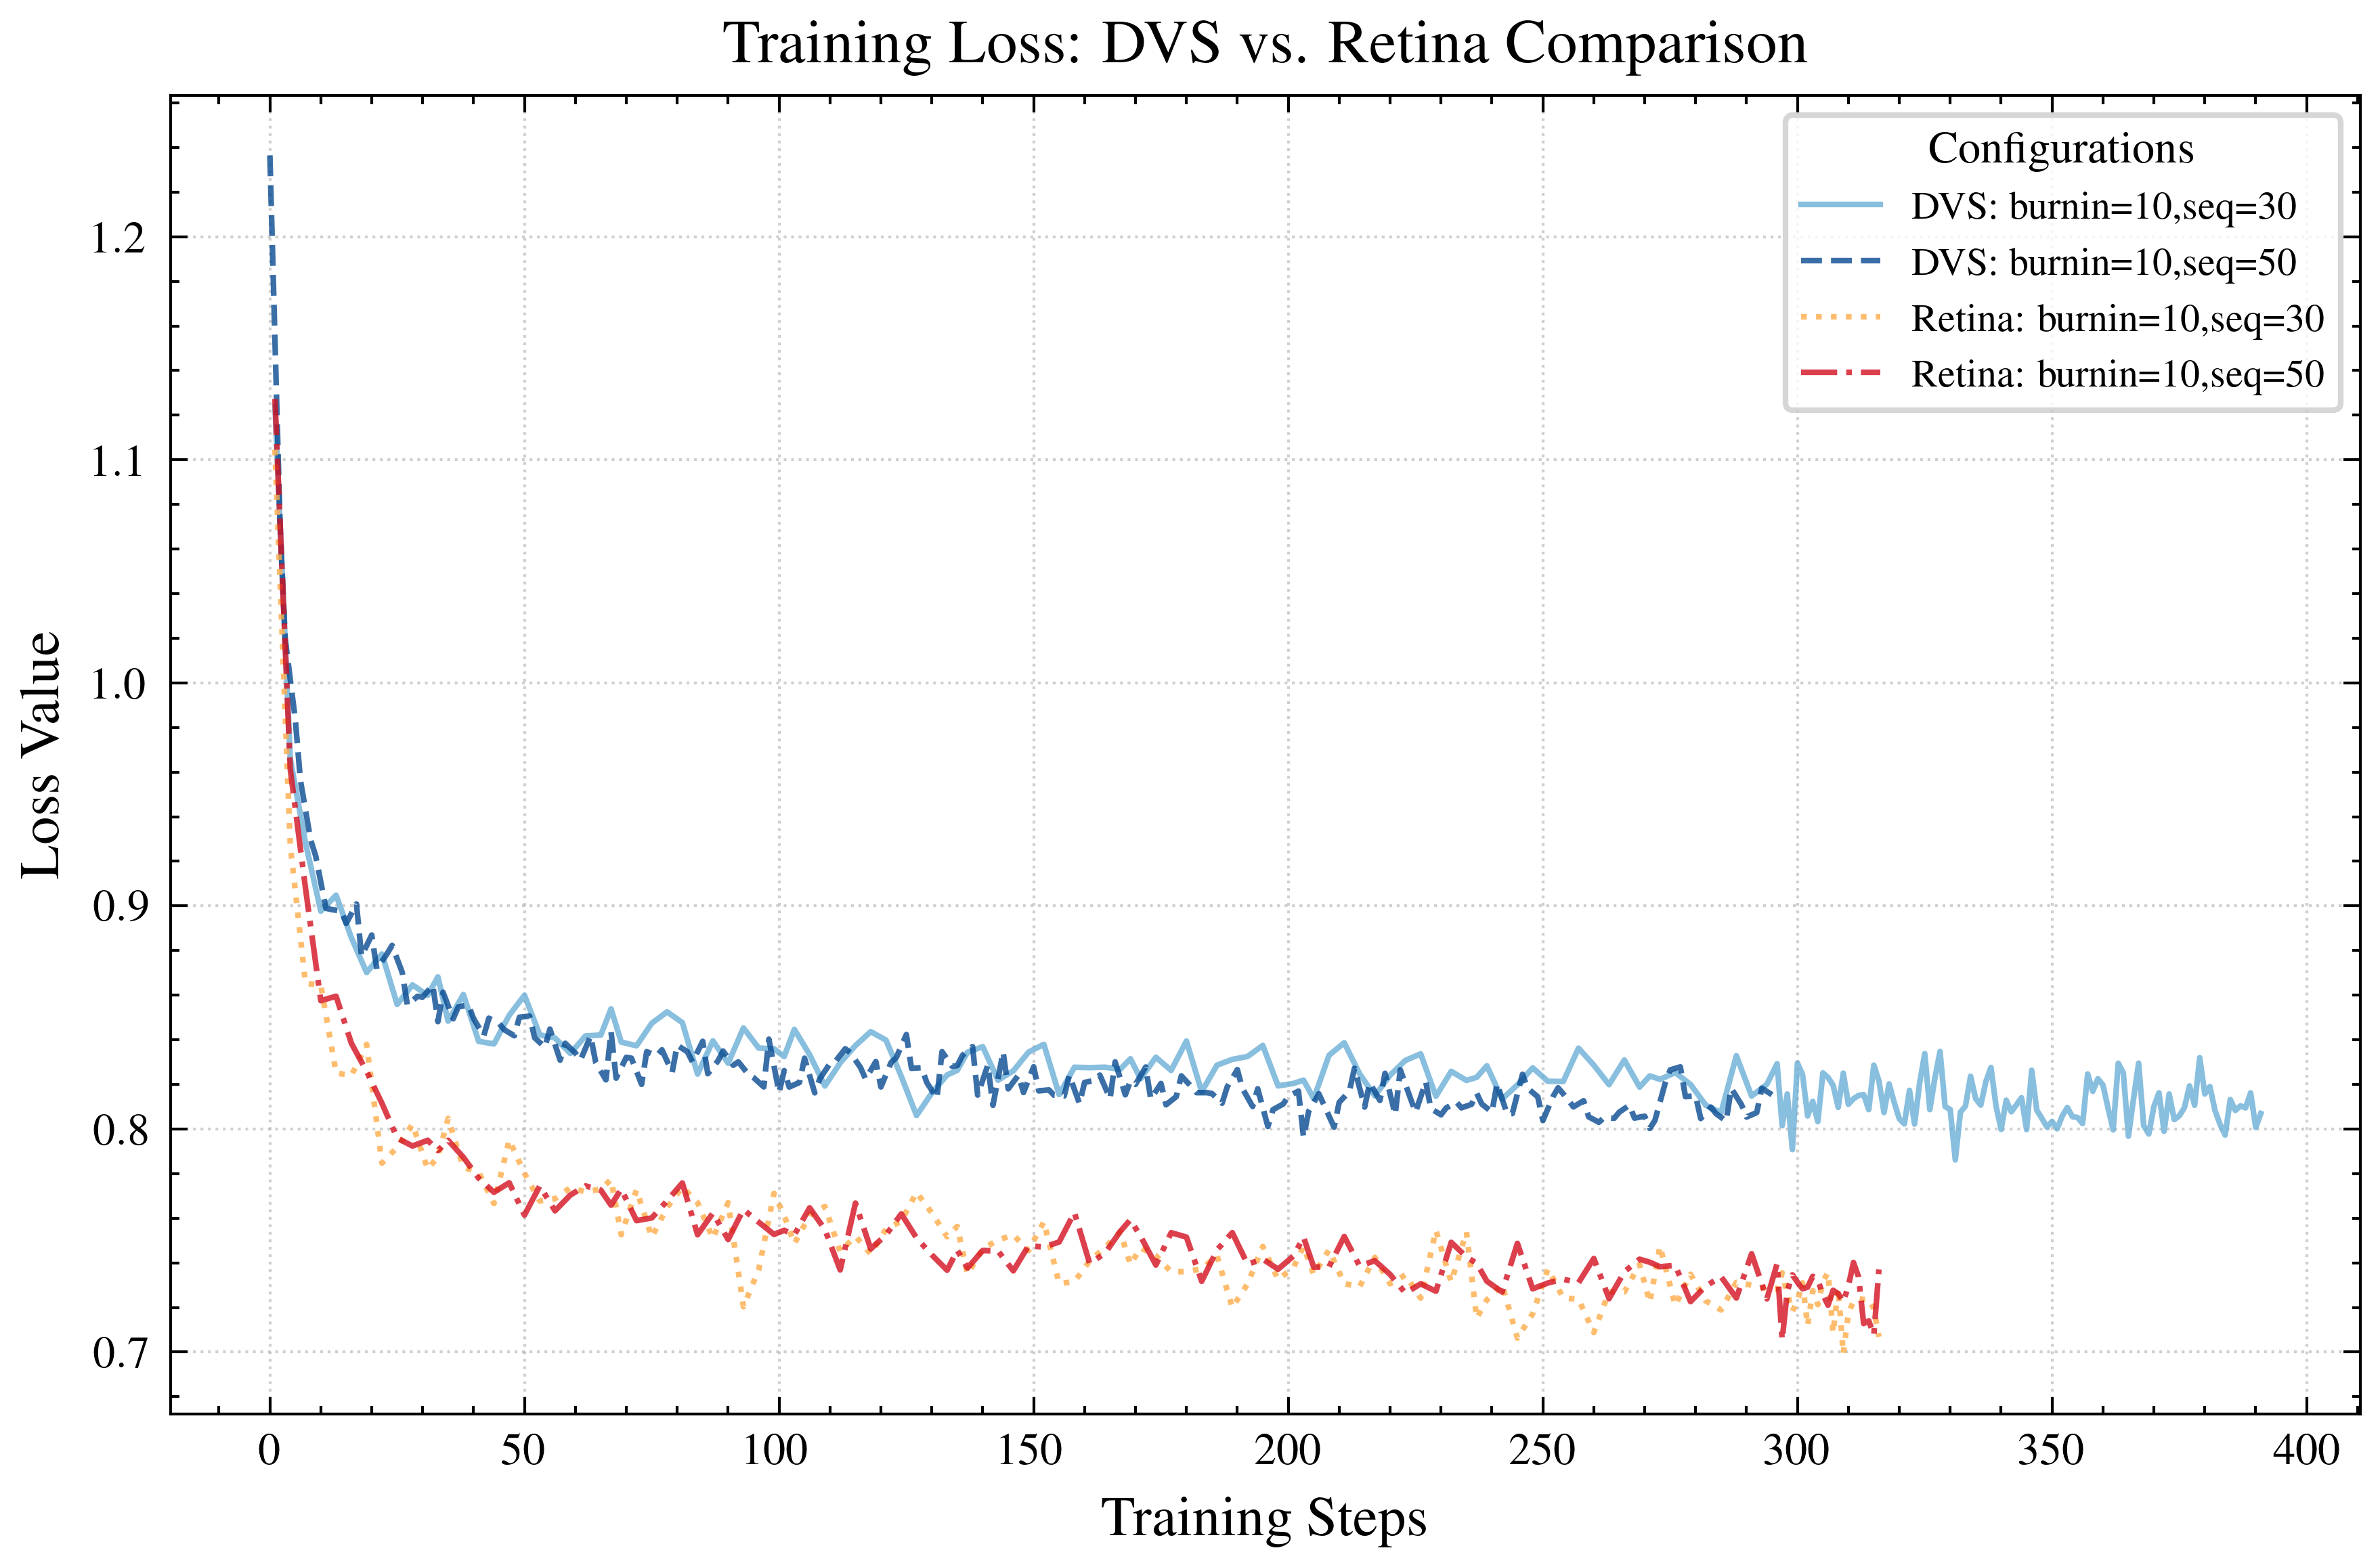

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

plt.style.use(['science', 'ieee']) 

dvs_label_names = ["burnin=10,seq=30",
                   "burnin=10,seq=50"]
retina_label_names = ["burnin=10,seq=30",
                   "burnin=10,seq=50"]

def plot_loss_data(df, dvs_group, dvs_labels, 
                   retina_group, retina_labels, 
                   is_train, smoothing=0.0):
    fig, ax = plt.subplots(figsize=(6, 4))
    
    prefix = "Training" if is_train else "Validation"
    
    # 1. Generate color palettes
    # Using Blues for DVS and YlOrRd for Retina
    # We take a subset of the colormap (e.g., 0.4 to 0.9) to avoid colors that are too light
    dvs_colors = plt.cm.Blues(np.linspace(0.5, 0.9, len(dvs_group)))
    retina_colors = plt.cm.YlOrRd(np.linspace(0.4, 0.8, len(retina_group)))

    # 2. Plot DVS Group
    for i, col in enumerate(dvs_group):
        data = df[col].dropna()
        label = dvs_labels[i]
        color = dvs_colors[i]
        
        if smoothing > 0:
            smoothed = data.ewm(alpha=1-smoothing).mean()
            ax.plot(data.index, smoothed, label=f"DVS: {label}", 
                    color=color, linewidth=1.2)
            # Faint raw data line
            ax.plot(data.index, data, color=color, linewidth=0.8, alpha=0.25)
        else:
            ax.plot(data.index, data, label=f"DVS: {label}", 
                    color=color, linewidth=1.0, alpha=0.8)

    # 3. Plot Retina Group
    for i, col in enumerate(retina_group):
        data = df[col].dropna()
        label = retina_labels[i]
        color = retina_colors[i]
        
        if smoothing > 0:
            smoothed = data.ewm(alpha=1-smoothing).mean()
            ax.plot(data.index, smoothed, label=f"Retina: {label}", 
                    color=color, linewidth=1.2)
            # Faint raw data line
            ax.plot(data.index, data, color=color, linewidth=0.8, alpha=0.15)
        else:
            ax.plot(data.index, data, label=f"Retina: {label}", 
                    color=color, linewidth=1.0, alpha=0.8)

    # 4. Polish the graph
    ax.set_xlabel(f'{prefix} Steps', fontsize=10)
    ax.set_ylabel(r'Loss Value', fontsize=10)
    ax.set_title(f'{prefix} Loss: DVS vs. Retina Comparison', fontsize=11, fontweight='bold')
    
    # Legend - placing it slightly outside or in a clear spot
    ax.legend(title='Configurations', fontsize=7, title_fontsize=8, 
              loc='upper right', frameon=True)
    
    ax.grid(True, linestyle=':', alpha=0.6)
    
    # Optional: use log scale if loss values vary by orders of magnitude
    # ax.set_yscale('log')
    
    plt.tight_layout()
    
    # Save with high DPI for publications
    file_name = f'saliency_{prefix.lower()}_loss.png'
    plt.savefig(file_name, dpi=300, bbox_inches='tight')
    print(f"Plot saved as {file_name}")
    plt.show()

# Usage with your dataframe
plot_loss_data(intensity_train_csv, 
               dvs_group_train, dvs_label_names,
               retina_group_train, retina_label_names, is_train=True, smoothing=0.0)

In [6]:
dvs_train = intensity_train_csv[dvs_group_train]
retina_train = intensity_train_csv[retina_group_train]

print("intensity DVS train min :", np.min(intensity_train_csv[dvs_group_train]))
print("intensity retina train min :", np.min(intensity_train_csv[retina_group_train]))

intensity DVS train min : 0.7861435057388412
intensity retina train min : 0.6991305100145163


In [7]:
import pandas as pd
import numpy as np

N = 20

def get_final_metrics(df, columns, n=5):
    """
    Extracts the average of the last N non-NaN values for a list of columns.
    """
    results = {}
    for col in columns:
        # 1. Drop NaNs to get the actual sequence of recordings
        clean_series = df[col].dropna()
        
        # 2. Take the last N values
        last_n_values = clean_series.tail(n)
        
        # 3. Calculate mean
        results[col] = last_n_values.mean()
        
    return results


dvs_averages = get_final_metrics(intensity_train_csv, dvs_group_train, n=N)
retina_averages = get_final_metrics(intensity_train_csv, retina_group_train, n=N)

# Displaying results clearly
print(f"--- Final Average Loss (Last {N} steps) ---")
print("\nDVS Group:")
for name, val in dvs_averages.items():
    print(f"{name}: {val:.4f}")


print("\nRetina Group:")
for name, val in retina_averages.items():
    print(f"{name}: {val:.4f}")

--- Final Average Loss (Last 20 steps) ---

DVS Group:
FIREnetwork_DVS2_seq=30 - train_loss_epoch: 0.8102
FIREnetwork_DVS_seq=50 - train_loss_epoch: 0.8115

Retina Group:
FIRE_saliency_p2=1.0_20251128_082440 - train_loss_epoch: 0.7218
FIRE_saliency_seq=50_gk5_20251201_014614 - train_loss_epoch: 0.7260


# Validation 

In [8]:
dvs_group_val = ['FIREnetwork_DVS2_seq=30 - val_loss_epoch',
                   'FIREnetwork_DVS_seq=50 - val_loss_epoch']

retina_group_val = ['FIRE_saliency_p2=1.0_20251128_082440 - val_loss_epoch',
                      'FIRE_saliency_seq=50_gk5_20251201_014614 - val_loss_epoch']
os.listdir()
intensity_val_csv = pd.read_csv(os.path.join("analysis", "retina_val_saliency.csv"))
print(intensity_val_csv.columns)

Index(['Step', 'FIRE_saliency_seq=50_gk5_20251201_014614 - val_loss_epoch',
       'FIRE_saliency_seq=50_gk5_20251201_014614 - val_loss_epoch__MIN',
       'FIRE_saliency_seq=50_gk5_20251201_014614 - val_loss_epoch__MAX',
       'FIREnetwork_DVS_seq=50 - val_loss_epoch',
       'FIREnetwork_DVS_seq=50 - val_loss_epoch__MIN',
       'FIREnetwork_DVS_seq=50 - val_loss_epoch__MAX',
       'FIRE_saliency_p2=1.0_20251128_082440 - val_loss_epoch',
       'FIRE_saliency_p2=1.0_20251128_082440 - val_loss_epoch__MIN',
       'FIRE_saliency_p2=1.0_20251128_082440 - val_loss_epoch__MAX',
       'FIREnetwork_DVS2_seq=30 - val_loss_epoch',
       'FIREnetwork_DVS2_seq=30 - val_loss_epoch__MIN',
       'FIREnetwork_DVS2_seq=30 - val_loss_epoch__MAX'],
      dtype='str')


Plot saved as saliency_validation_loss.png


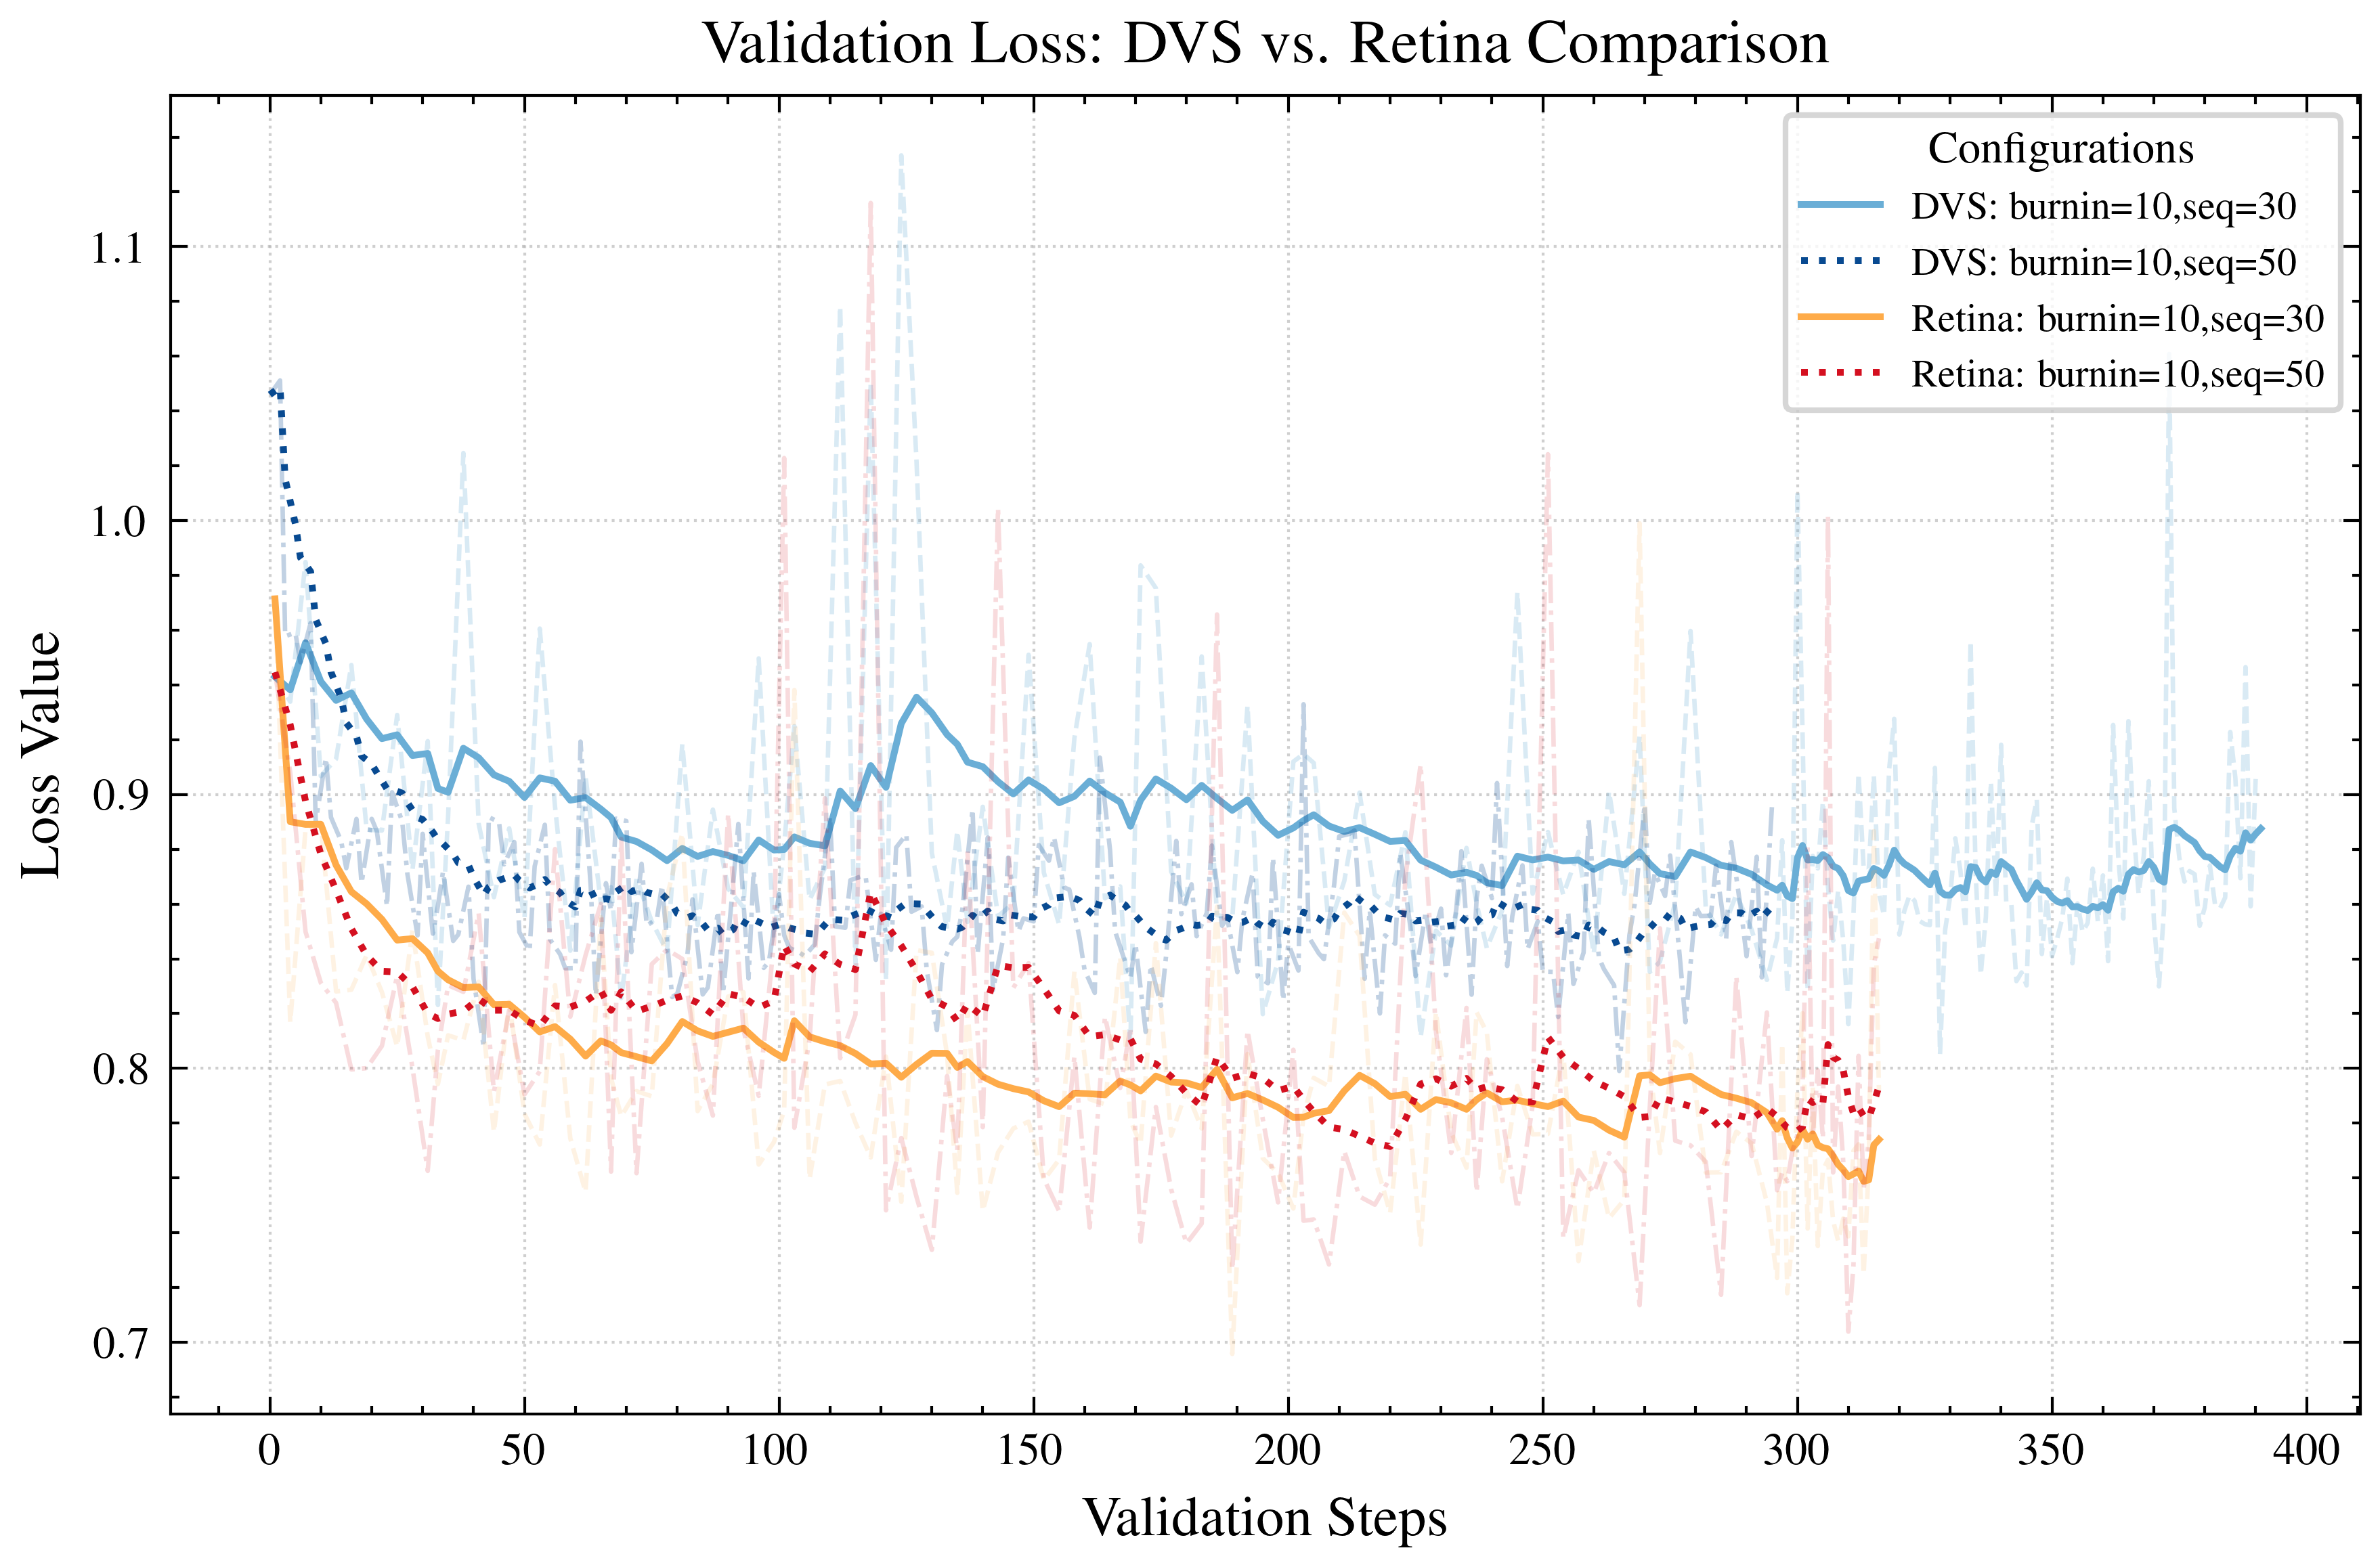

In [9]:
plot_loss_data(intensity_val_csv, 
               dvs_group_val, dvs_label_names,
               retina_group_val, retina_label_names, smoothing=0.9, is_train=False)

In [10]:
print(np.min(intensity_val_csv[dvs_group_val]))
print(np.min(intensity_val_csv[retina_group_val]))

0.7990590397800718
0.6957454161210493


In [11]:
dvs_averages = get_final_metrics(intensity_val_csv, dvs_group_val, n=N)
retina_averages = get_final_metrics(intensity_val_csv, retina_group_val, n=N)

# Displaying results clearly
print(f"--- Final Average Loss (Last {N} steps) ---")
print("\nDVS Group:")
for name, val in dvs_averages.items():
    print(f"{name}: {val:.4f}")


print("\nRetina Group:")
for name, val in retina_averages.items():
    print(f"{name}: {val:.4f}")

--- Final Average Loss (Last 20 steps) ---

DVS Group:
FIREnetwork_DVS2_seq=30 - val_loss_epoch: 0.8891
FIREnetwork_DVS_seq=50 - val_loss_epoch: 0.8606

Retina Group:
FIRE_saliency_p2=1.0_20251128_082440 - val_loss_epoch: 0.7676
FIRE_saliency_seq=50_gk5_20251201_014614 - val_loss_epoch: 0.7931


# Ablation studies

## Feedback Type

<>:52: SyntaxWarning: invalid escape sequence '\%'
<>:59: SyntaxWarning: invalid escape sequence '\%'
<>:65: SyntaxWarning: invalid escape sequence '\%'
<>:52: SyntaxWarning: invalid escape sequence '\%'
<>:59: SyntaxWarning: invalid escape sequence '\%'
<>:65: SyntaxWarning: invalid escape sequence '\%'
/tmp/ipykernel_1097/1481198722.py:52: SyntaxWarning: invalid escape sequence '\%'
  line = ax2.plot(x, grids_occupancy, color='C1', marker='o', markersize=4, label='Occupancy (\%)')
/tmp/ipykernel_1097/1481198722.py:59: SyntaxWarning: invalid escape sequence '\%'
  ax2.annotate(f'{txt:.2f}\%',
/tmp/ipykernel_1097/1481198722.py:65: SyntaxWarning: invalid escape sequence '\%'
  ax2.set_ylabel('Grid Occupancy (\%)', color='C1')


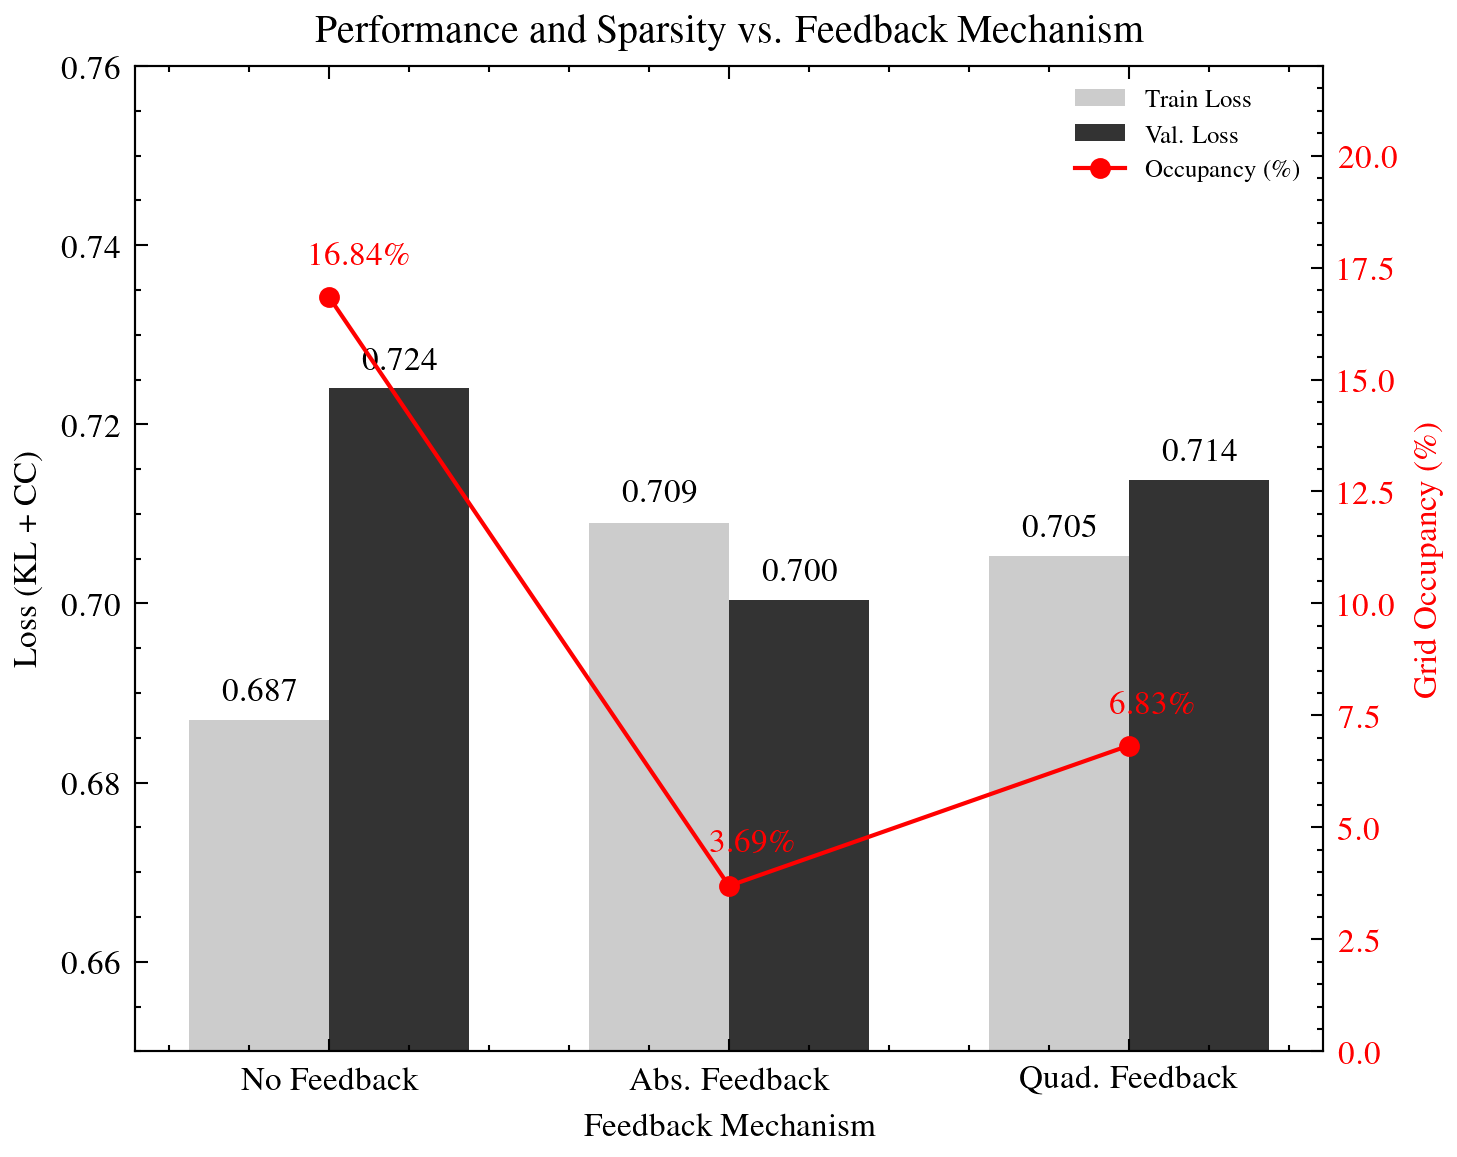

In [12]:
import matplotlib.pyplot as plt
import scienceplots
import numpy as np

feedback_train_loss = pd.read_csv(os.path.join("analysis", "feedback_train_loss.csv"))
feedback_val_loss = pd.read_csv(os.path.join("analysis", "feedback_val_loss.csv"))


train_columns = ['Fire_saliency_no_fb_20251217_190136 - train_loss_epoch',
                 'Fire_saliency_abs_fb_20251218_114456 - train_loss_epoch',
                 'Fire_saliency_quad_fb_20251218_031053 - train_loss_epoch']

val_columns = ['Fire_saliency_no_fb_20251217_190136 - val_loss_epoch',
               'Fire_saliency_abs_fb_20251218_114456 - val_loss_epoch',
               'Fire_saliency_quad_fb_20251218_031053 - val_loss_epoch']

# Data
names = ["No Feedback", "Abs. Feedback", "Quad. Feedback"]
grids_occupancy = np.array([0.16845, 0.03694, 0.068282]) * 100
val_loss = [0.72405, 0.70042, 0.7138]
train_loss = [0.687, 0.709, 0.70531]

plt.style.use(['science', 'ieee'])
fig, ax1 = plt.subplots(figsize=(5, 4), dpi=300)

x = np.arange(len(names))
width = 0.35

# Plot Train and Val Loss (Grouped Bars)
rects1 = ax1.bar(x - width/2, train_loss, width, label='Train Loss', color='gray', alpha=0.4)
rects2 = ax1.bar(x + width/2, val_loss, width, label='Val. Loss', color='C0', alpha=0.8)

# Add text labels above bars for Loss
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax1.annotate(f'{height:.3f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=8)


ax1.set_xlabel('Feedback Mechanism')
ax1.set_ylabel('Loss (KL + CC)')
ax1.set_xticks(x)
ax1.set_xticklabels(names)
ax1.set_ylim(0.65, 0.76) # Increased slightly to fit labels

# Secondary axis for Occupancy
ax2 = ax1.twinx()
line = ax2.plot(x, grids_occupancy, color='C1', marker='o', markersize=4, label='Occupancy (\%)')

autolabel(rects1)
autolabel(rects2)

# Add text labels next to data points for Occupancy
for i, txt in enumerate(grids_occupancy):
    ax2.annotate(f'{txt:.2f}\%', 
                 (x[i]-0.1, grids_occupancy[i] + 0.9), 
                 xytext=(5, 0), 
                 textcoords='offset points',
                 va='center', color='C1', weight='bold', fontsize=8)

ax2.set_ylabel('Grid Occupancy (\%)', color='C1')
ax2.set_ylim(0, 22) # Increased slightly to fit labels
ax2.tick_params(axis='y', labelcolor='C1')

# Unified Legend
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper right', fontsize='6')

plt.title('Performance and Sparsity vs. Feedback Mechanism')
fig.tight_layout()
plt.savefig('feedback_comparison_detailed.png')
plt.show()

<>:54: SyntaxWarning: invalid escape sequence '\%'
<>:74: SyntaxWarning: invalid escape sequence '\%'
<>:81: SyntaxWarning: invalid escape sequence '\%'
<>:54: SyntaxWarning: invalid escape sequence '\%'
<>:74: SyntaxWarning: invalid escape sequence '\%'
<>:81: SyntaxWarning: invalid escape sequence '\%'
/tmp/ipykernel_1097/4080843072.py:54: SyntaxWarning: invalid escape sequence '\%'
  label='Occupancy (\%)', zorder=3)
/tmp/ipykernel_1097/4080843072.py:74: SyntaxWarning: invalid escape sequence '\%'
  ax2.annotate(f'{txt:.2f}\%',
/tmp/ipykernel_1097/4080843072.py:81: SyntaxWarning: invalid escape sequence '\%'
  ax2.set_ylabel('Grid Occupancy (\%)', color='C1')


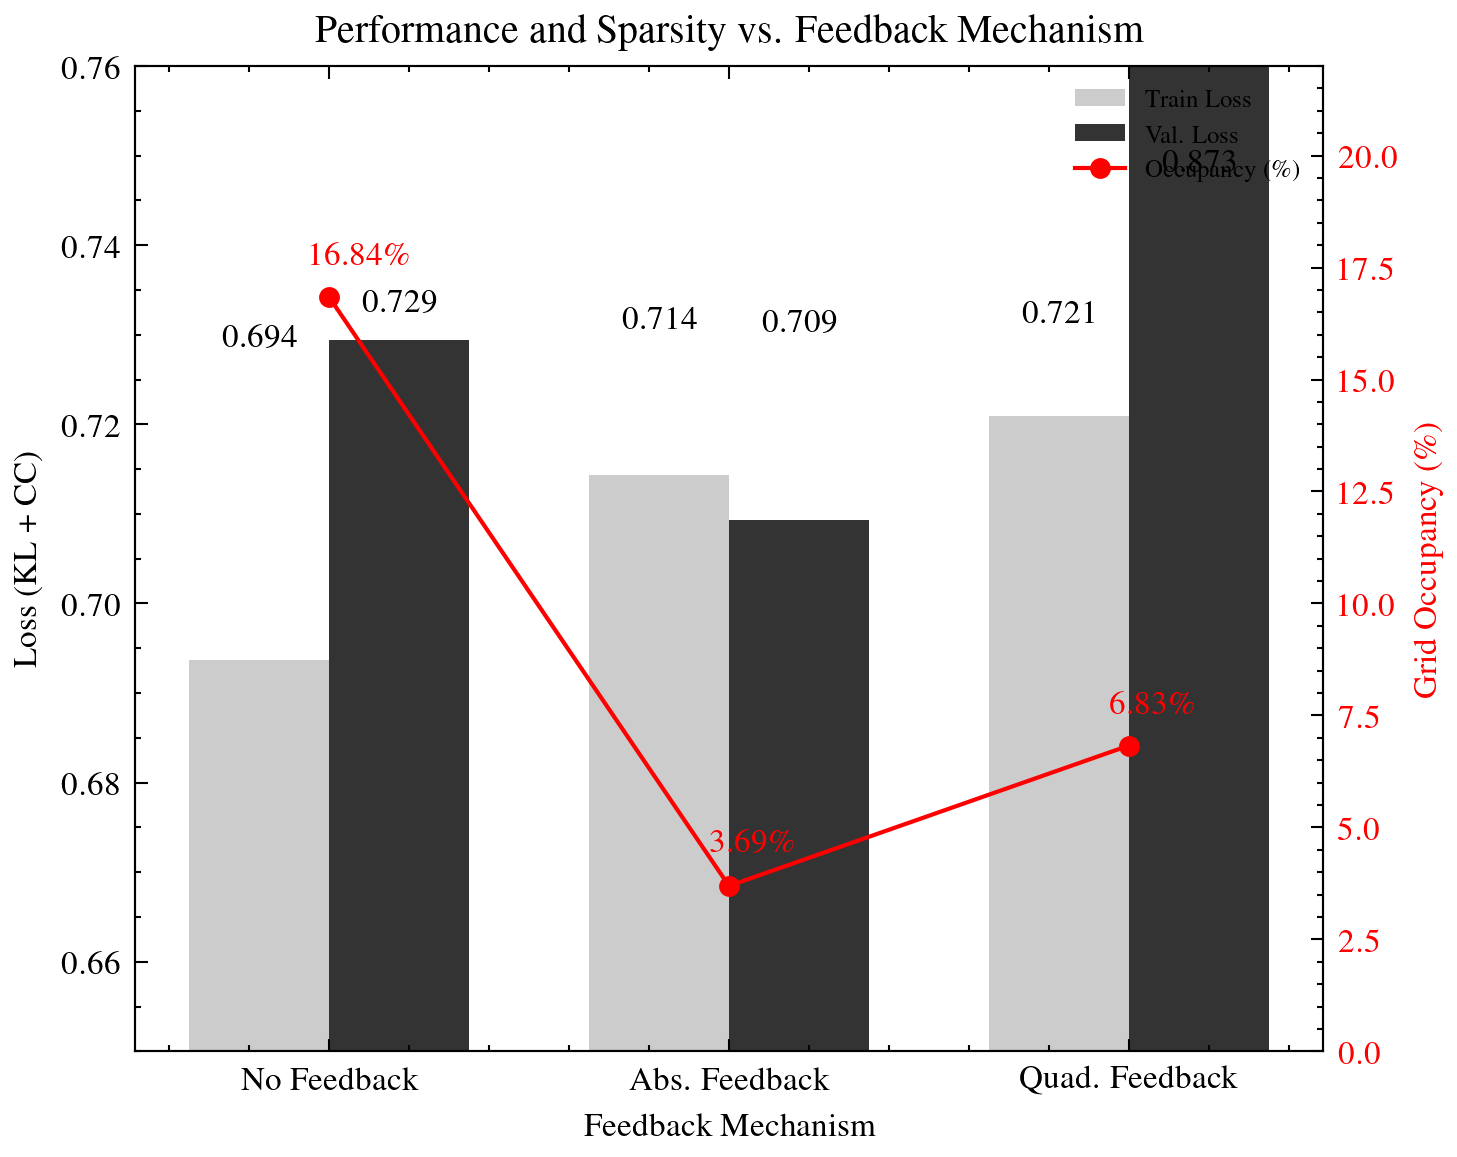

In [13]:
import matplotlib.pyplot as plt
import scienceplots
import numpy as np

feedback_train_loss = pd.read_csv(os.path.join("analysis", "feedback_train_loss.csv"))
feedback_val_loss = pd.read_csv(os.path.join("analysis", "feedback_val_loss.csv"))


train_columns = ['Fire_saliency_no_fb_20251217_190136 - train_loss_epoch',
                 'Fire_saliency_abs_fb_20251218_114456 - train_loss_epoch',
                 'Fire_saliency_quad_fb_20251218_031053 - train_loss_epoch']

val_columns = ['Fire_saliency_no_fb_20251217_190136 - val_loss_epoch',
               'Fire_saliency_abs_fb_20251218_114456 - val_loss_epoch',
               'Fire_saliency_quad_fb_20251218_031053 - val_loss_epoch']

# 2. Calculate Statistics (Top-5 Mean)
train_loss = []
for col in train_columns:
    # Mean of the 5 best (smallest) loss values
    mean_best = feedback_train_loss[col].dropna().nsmallest(5).mean()
    train_loss.append(mean_best)

val_loss = []
for col in val_columns:
    mean_best = feedback_val_loss[col].dropna().nsmallest(5).mean()
    val_loss.append(mean_best)

# Data for Plotting
names = ["No Feedback", "Abs. Feedback", "Quad. Feedback"]
grids_occupancy = np.array([0.16845, 0.03694, 0.068282]) * 100

# 3. Plotting
plt.style.use(['science', 'ieee'])
fig, ax1 = plt.subplots(figsize=(5, 4), dpi=300)

x = np.arange(len(names))
width = 0.35

# Plot Train and Val Loss (Grouped Bars)
rects1 = ax1.bar(x - width/2, train_loss, width, label='Train Loss', color='gray', alpha=0.4)
rects2 = ax1.bar(x + width/2, val_loss, width, label='Val. Loss', color='C0', alpha=0.8)

ax1.set_xlabel('Feedback Mechanism')
ax1.set_ylabel('Loss (KL + CC)')
ax1.set_xticks(x)
ax1.set_xticklabels(names)
ax1.set_ylim(0.65, 0.76) 

# Secondary axis for Occupancy
ax2 = ax1.twinx()
# Plot Line with zorder=3 to sit on top of bars
line = ax2.plot(x, grids_occupancy, color='C1', marker='o', markersize=4, 
                label='Occupancy (\%)', zorder=3)

# Add text labels above bars for Loss
# We use the ax2.annotate trick with xycoords from ax1 to ensure text is on top layer
def autolabel(rects, ax_target):
    for rect in rects:
        height = rect.get_height()
        ax2.annotate(f'{height:.3f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xycoords=ax1.get_xaxis_transform(), # Use ax1 coordinates
                    xytext=(0, 3), 
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=8,
                    zorder=100) # High zorder to stay on top

autolabel(rects1, ax1)
autolabel(rects2, ax1)

# Add text labels next to data points for Occupancy
for i, txt in enumerate(grids_occupancy):
    ax2.annotate(f'{txt:.2f}\%', 
                 (x[i]-0.1, grids_occupancy[i] + 0.9), 
                 xytext=(5, 0), 
                 textcoords='offset points',
                 va='center', color='C1', weight='bold', fontsize=8,
                 zorder=101)

ax2.set_ylabel('Grid Occupancy (\%)', color='C1')
ax2.set_ylim(0, 22)
ax2.tick_params(axis='y', labelcolor='C1')

# Unified Legend
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper right', fontsize='6')

plt.title('Performance and Sparsity vs. Feedback Mechanism')
fig.tight_layout()
plt.savefig('feedback_comparison_detailed_3.png')
plt.show()

## Bandwidth

In [14]:
bandwidth_train = pd.read_csv(os.path.join("analysis", "bandwidth_train.csv"))
bandwidth_val = pd.read_csv(os.path.join("analysis", "bandwidth_val.csv"))

train_columns = ['Fire_saliency_best1_b1_20260106_231638 - train_loss_epoch',
                 'Fire_saliency_best1_b2_20260107_133556 - train_loss_epoch',
                 'Fire_saliency_best1_b3_20260108_021703 - train_loss_epoch',
                 'Fire_saliency_best1_b5_20260109_114513 - train_loss_epoch',
                 'Fire_saliency_best1_b5_20260110_021334 - train_loss_epoch',
                 'Fire_saliency_best1_b5_20260108_161937 - train_loss_epoch']

val_columns = ['Fire_saliency_best1_b1_20260106_231638 - val_loss_epoch',
                 'Fire_saliency_best1_b2_20260107_133556 - val_loss_epoch',
                 'Fire_saliency_best1_b3_20260108_021703 - val_loss_epoch',
                 'Fire_saliency_best1_b5_20260109_114513 - val_loss_epoch',
                 'Fire_saliency_best1_b5_20260110_021334 - val_loss_epoch',
                 'Fire_saliency_best1_b5_20260108_161937 - val_loss_epoch']

p_coeff = [0.9, 1.05, 1.1, 1.35, 1.4, 1.5]
occupancy = [0.013515, 0.026191, 0.03198, 0.08119, 0.09811, 0.14947]

<>:46: SyntaxWarning: invalid escape sequence '\%'
<>:46: SyntaxWarning: invalid escape sequence '\%'
/tmp/ipykernel_1097/4236819062.py:46: SyntaxWarning: invalid escape sequence '\%'
  ax1.set_xlabel('Event Occupancy (\%)')


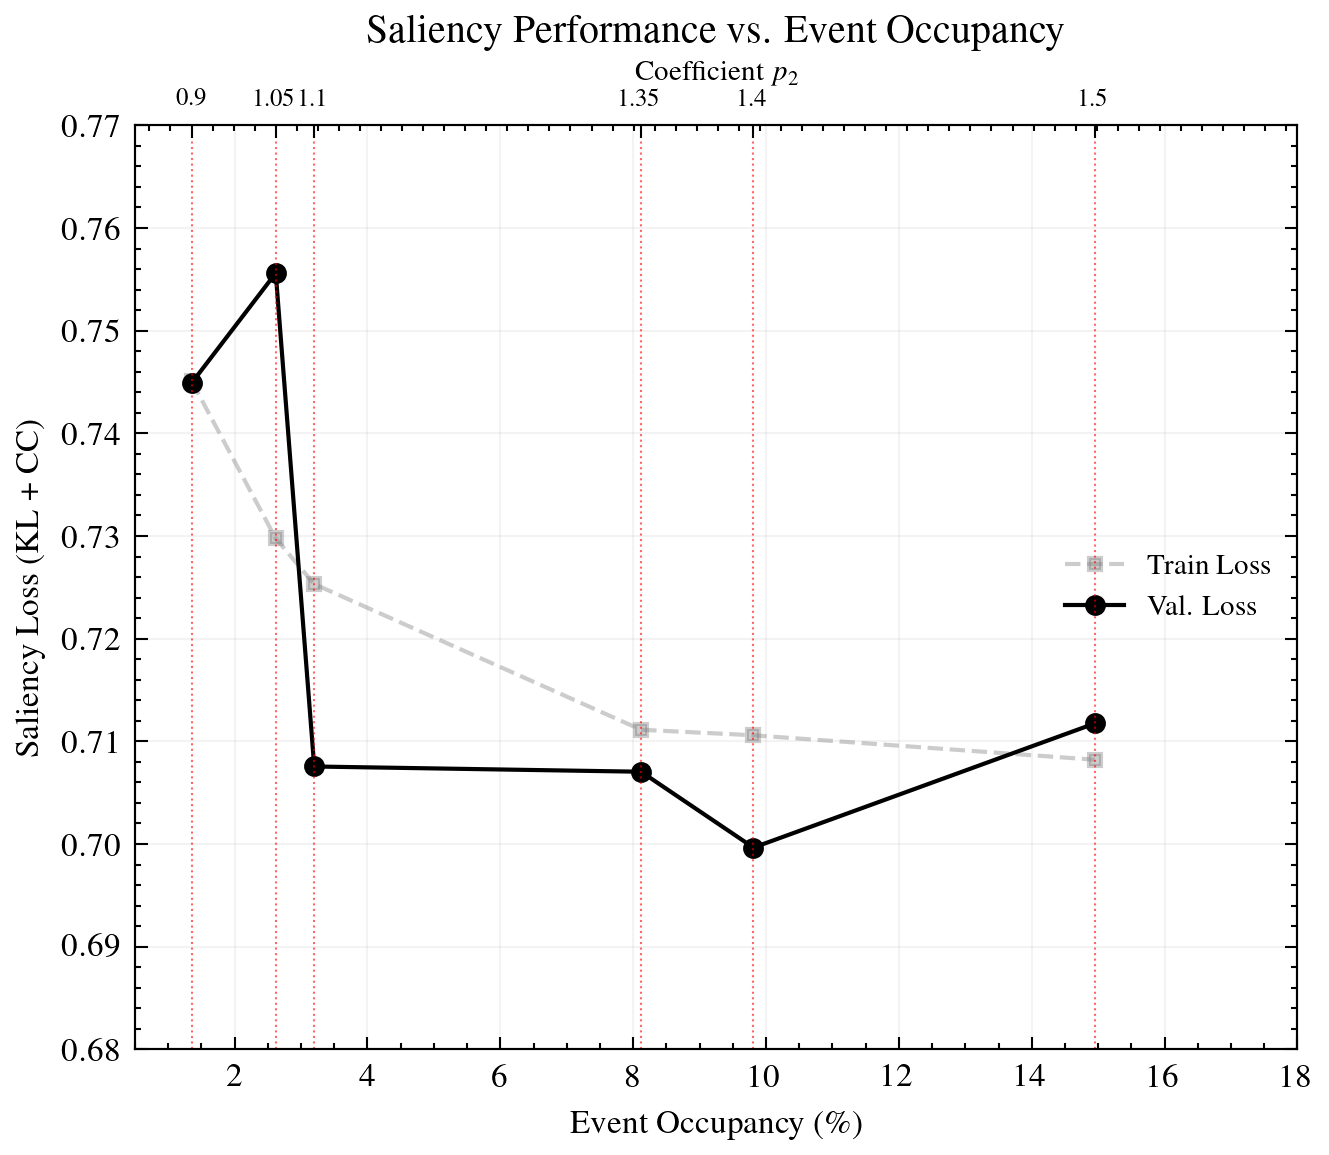

In [15]:
bandwidth_train = pd.read_csv(os.path.join("analysis", "bandwidth_train.csv"))
bandwidth_val = pd.read_csv(os.path.join("analysis", "bandwidth_val.csv"))

train_columns = ['Fire_saliency_best1_b1_20260106_231638 - train_loss_epoch',
                 'Fire_saliency_best1_b2_20260107_133556 - train_loss_epoch',
                 'Fire_saliency_best1_b3_20260108_021703 - train_loss_epoch',
                 'Fire_saliency_best1_b5_20260109_114513 - train_loss_epoch',
                 'Fire_saliency_best1_b5_20260110_021334 - train_loss_epoch',
                 'Fire_saliency_best1_b5_20260108_161937 - train_loss_epoch']

val_columns = ['Fire_saliency_best1_b1_20260106_231638 - val_loss_epoch',
                 'Fire_saliency_best1_b2_20260107_133556 - val_loss_epoch',
                 'Fire_saliency_best1_b3_20260108_021703 - val_loss_epoch',
                 'Fire_saliency_best1_b5_20260109_114513 - val_loss_epoch',
                 'Fire_saliency_best1_b5_20260110_021334 - val_loss_epoch',
                 'Fire_saliency_best1_b5_20260108_161937 - val_loss_epoch']

p_coeff = [0.9, 1.05, 1.1, 1.35, 1.4, 1.5]
occupancy = [0.013515, 0.026191, 0.03198, 0.08119, 0.09811, 0.14947]

import matplotlib.pyplot as plt
import scienceplots
import numpy as np
from matplotlib.ticker import ScalarFormatter

p_coeff = [0.9, 1.05, 1.1, 1.35, 1.4, 1.5]
occupancy = 100 * np.array([0.013515, 0.026191, 0.031982, 0.081188, 0.09811, 0.14947])
val_loss = [0.74489, 0.75561, 0.70755, 0.70704, 0.69965, 0.71174]
train_loss = [0.74511, 0.72976, 0.72532, 0.71113, 0.71059, 0.70821]

#plt.style.use(['science', 'ieee'])
fig, ax1 = plt.subplots(figsize=(5, 4), dpi=300)

# Sort data for clean line plotting
sort_idx = np.argsort(occupancy)
occ_sorted = occupancy[sort_idx]
val_sorted = np.array(val_loss)[sort_idx]
train_sorted = np.array(train_loss)[sort_idx]
p_sorted = np.array(p_coeff)[sort_idx]

# 1. Main Plot
ax1.plot(occ_sorted, train_sorted, 's--', color='gray', alpha=0.4, label='Train Loss', markersize=3)
ax1.plot(occ_sorted, val_sorted, 'o-', color='C0', label='Val. Loss', markersize=4)

# 2. X-Axis Formatting (Bottom: Occupancy)
ax1.set_xlabel('Event Occupancy (\%)')
ax1.set_ylabel('Saliency Loss (KL + CC)')
ax1.set_xlim(0.5, 18)
ax1.set_ylim(0.68, 0.77)

# 3. TOP X-AXIS: Mapping Occupancy to p2 values
ax_top = ax1.twiny()
ax_top.set_xlim(ax1.get_xlim())
ax_top.set_xticks(occ_sorted)
ax_top.set_xticklabels([f'{p}' for p in p_sorted], fontsize=6)
ax_top.set_xlabel(r'Coefficient $p_2$', fontsize=7, labelpad=5)

# 4. ADDING THE SECONDARY GRID (Vertical bars for p2)
# We set the grid for the top axis to show only vertical lines 
ax_top.grid(True, axis='x', ls=':', color='C1', alpha=0.6)

# Set ticks exactly where the data points are
ax_top.set_xticks(occ_sorted)
# Label them with the p2 coefficients
ax_top.set_xticklabels([f'{p}' for p in p_sorted], fontsize=6)
ax_top.set_xlabel(r'Coefficient $p_2$', fontsize=7, labelpad=2)

# Clean up
ax1.grid(True, which="major", ls="-", alpha=0.15)
ax1.legend(loc='center right', fontsize=7)

plt.title('Saliency Performance vs. Event Occupancy', pad=20)
plt.savefig('sparsity_performance_sweep.png', bbox_inches='tight')
plt.show()

<>:60: SyntaxWarning: invalid escape sequence '\%'
<>:60: SyntaxWarning: invalid escape sequence '\%'
/tmp/ipykernel_1097/1358142637.py:60: SyntaxWarning: invalid escape sequence '\%'
  ax1.set_xlabel('Event Occupancy (\%)')


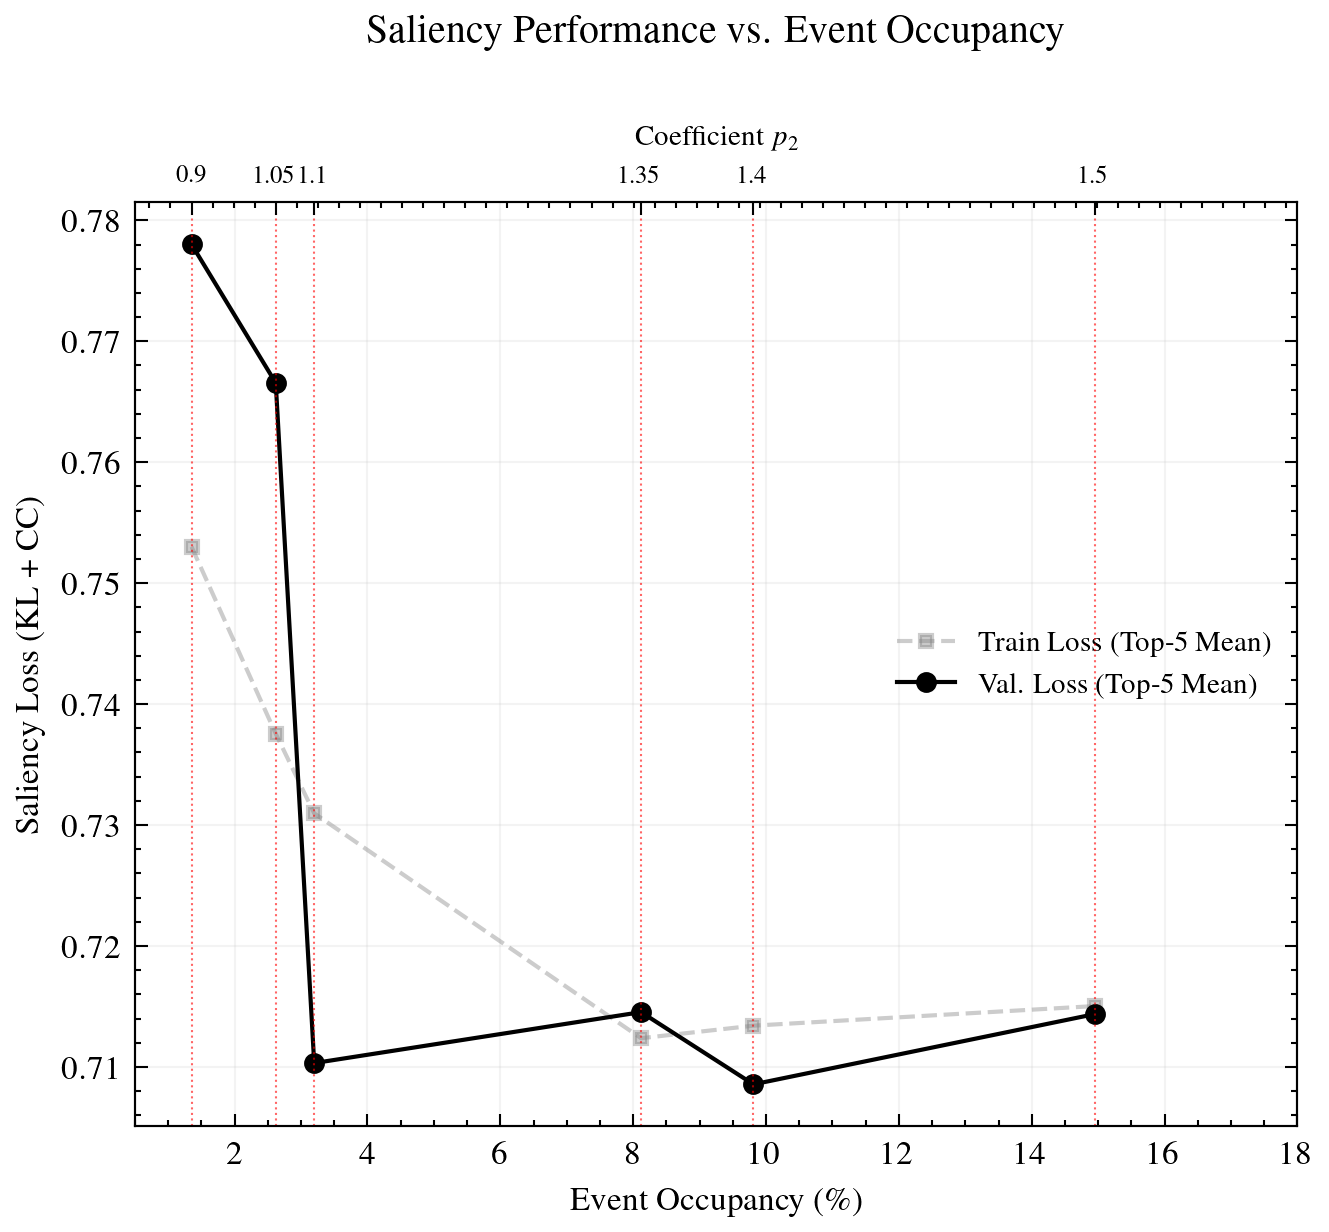

In [16]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import scienceplots
from matplotlib.ticker import ScalarFormatter

# 1. Load Data
bandwidth_train = pd.read_csv(os.path.join("analysis", "bandwidth_train.csv"))
bandwidth_val = pd.read_csv(os.path.join("analysis", "bandwidth_val.csv"))

train_columns = ['Fire_saliency_best1_b1_20260106_231638 - train_loss_epoch',
                 'Fire_saliency_best1_b2_20260107_133556 - train_loss_epoch',
                 'Fire_saliency_best1_b3_20260108_021703 - train_loss_epoch',
                 'Fire_saliency_best1_b5_20260109_114513 - train_loss_epoch',
                 'Fire_saliency_best1_b5_20260110_021334 - train_loss_epoch',
                 'Fire_saliency_best1_b5_20260108_161937 - train_loss_epoch']

val_columns = ['Fire_saliency_best1_b1_20260106_231638 - val_loss_epoch',
                 'Fire_saliency_best1_b2_20260107_133556 - val_loss_epoch',
                 'Fire_saliency_best1_b3_20260108_021703 - val_loss_epoch',
                 'Fire_saliency_best1_b5_20260109_114513 - val_loss_epoch',
                 'Fire_saliency_best1_b5_20260110_021334 - val_loss_epoch',
                 'Fire_saliency_best1_b5_20260108_161937 - val_loss_epoch']

p_coeff = [0.9, 1.05, 1.1, 1.35, 1.4, 1.5]
# Precise occupancy values
occupancy = 100 * np.array([0.013515, 0.026191, 0.031982, 0.081188, 0.09811, 0.14947])

# 2. Calculate Statistics (Top-5 Mean)
val_loss = []
for col in val_columns:
    # Drop NaNs to handle potentially different run lengths
    # Take the mean of the 5 smallest (best) validation losses
    mean_best_5 = bandwidth_val[col].dropna().nsmallest(5).mean()
    val_loss.append(mean_best_5)

train_loss = []
for col in train_columns:
    # We apply the same logic to training for consistency
    mean_best_5 = bandwidth_train[col].dropna().nsmallest(5).mean()
    train_loss.append(mean_best_5)

# 3. Plotting
plt.style.use(['science', 'ieee'])
fig, ax1 = plt.subplots(figsize=(5, 4), dpi=300)

# Sort data for clean line plotting (by occupancy)
sort_idx = np.argsort(occupancy)
occ_sorted = occupancy[sort_idx]
val_sorted = np.array(val_loss)[sort_idx]
train_sorted = np.array(train_loss)[sort_idx]
p_sorted = np.array(p_coeff)[sort_idx]

# Main Plot
ax1.plot(occ_sorted, train_sorted, 's--', color='gray', alpha=0.4, label='Train Loss (Top-5 Mean)', markersize=3)
ax1.plot(occ_sorted, val_sorted, 'o-', color='C0', label='Val. Loss (Top-5 Mean)', markersize=4)

# X-Axis Formatting (Bottom: Occupancy)
ax1.set_xlabel('Event Occupancy (\%)')
ax1.set_ylabel('Saliency Loss (KL + CC)')
ax1.set_xlim(0.5, 18)
# ax1.set_ylim(0.68, 0.77) # Uncomment to fix Y range if needed

# Top X-Axis: Mapping Occupancy to p2 values
ax_top = ax1.twiny()
ax_top.set_xlim(ax1.get_xlim())

# Set ticks exactly where the data points are
ax_top.set_xticks(occ_sorted)
ax_top.set_xticklabels([f'{p}' for p in p_sorted], fontsize=6)
ax_top.set_xlabel(r'Coefficient $p_2$', fontsize=7, labelpad=5)

# Secondary Grid (Vertical bars for p2)
ax_top.grid(True, axis='x', ls=':', color='C1', alpha=0.6)

# Main Grid
ax1.grid(True, which="major", ls="-", alpha=0.15)
ax1.legend(loc='center right', fontsize=7)

plt.title('Saliency Performance vs. Event Occupancy', pad=20)
plt.savefig('sparsity_performance_sweep_robust.png', bbox_inches='tight')
plt.show()\
    

# Temporal map formulation

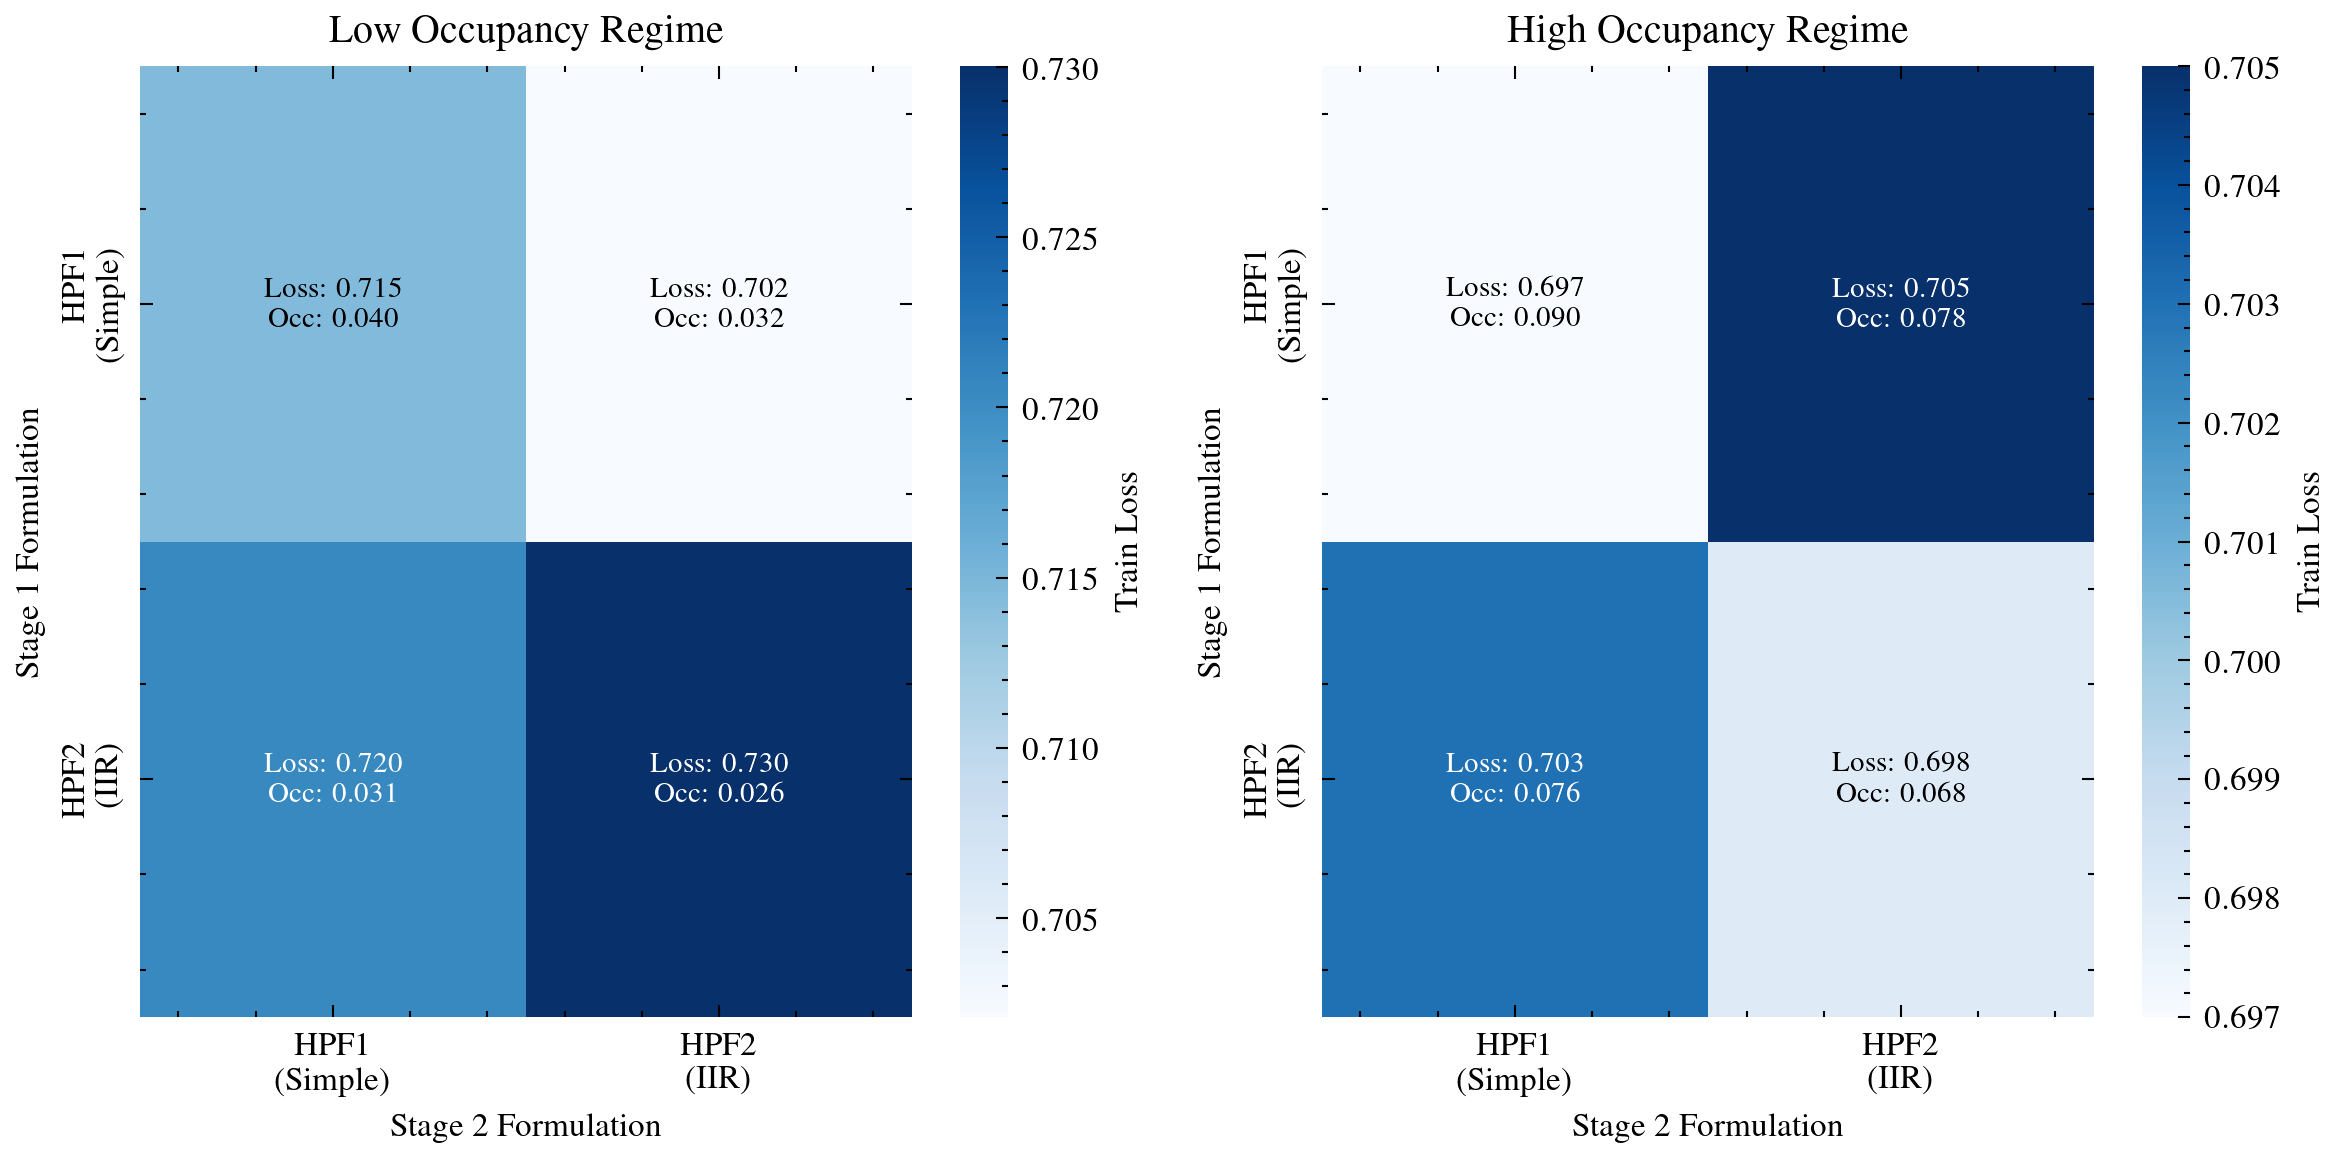

In [17]:
import seaborn as sns

# a pair of modes for (HPF1, HPF2)
# low occupancy regime
HPF_modes = [(0,0), (1,1), (0,1), (1,0)]
train_loss_lo = [0.71455, 0.73003, 0.70209, 0.72048]
occupancy_lo = [0.0398, 0.026101, 0.032155, 0.031357]

# higher occupancy regime ( larger p_2 values)
train_loss_ho = [0.697, 0.698, 0.705, 0.703] 
occupancy_ho = [0.09, 0.068, 0.078, 0.0765]


def create_matrix(modes, values):
    mat = np.zeros((2, 2))
    for (m1, m2), v in zip(modes, values):
        mat[m1, m2] = v
    return mat

mat_loss_lo = create_matrix(HPF_modes, train_loss_lo)
mat_occ_lo = create_matrix(HPF_modes, occupancy_lo)

mat_loss_ho = create_matrix(HPF_modes, train_loss_ho)
mat_occ_ho = create_matrix(HPF_modes, occupancy_ho)

# Style
plt.style.use(['science', 'ieee'])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4), dpi=300)

labels = ['HPF1\n(Simple)', 'HPF2\n(IIR)']

# Plotting function for consistency
def plot_regime_heatmap(ax, loss_mat, occ_mat, title):
    sns.heatmap(loss_mat, annot=False, cmap='Blues', ax=ax, cbar_kws={'label': 'Train Loss'})
    for i in range(2):
        for j in range(2):
            color = "white" if loss_mat[i,j] > np.median(loss_mat) else "black"
            ax.text(j+0.5, i+0.5, f'Loss: {loss_mat[i,j]:.3f}\nOcc: {occ_mat[i,j]:.3f}%',
                     ha='center', va='center', color=color, fontsize=7, fontweight='bold')
    ax.set_title(title)
    ax.set_xlabel('Stage 2 Formulation')
    ax.set_ylabel('Stage 1 Formulation')
    ax.set_xticks([0.5, 1.5])
    ax.set_xticklabels(labels)
    ax.set_yticks([0.5, 1.5])
    ax.set_yticklabels(labels)

plot_regime_heatmap(ax1, mat_loss_lo, mat_occ_lo, 'Low Occupancy Regime')
plot_regime_heatmap(ax2, mat_loss_ho, mat_occ_ho, 'High Occupancy Regime')

plt.tight_layout()
plt.savefig('hpf_ablation_heatmaps.png')
plt.show()

# Kernel sizes

In [18]:
os.listdir(".")

['spatial_kernel_ablation_final.png',
 'sparsity_performance_sweep.png',
 '.DS_Store',
 'retina-figs.pptx',
 'intensity_validation_loss.png',
 'sparsity_performance_sweep_robust - Copy.png:Zone.Identifier',
 'visualization_figures',
 '~$retina-figs.pptx',
 'saliency_training_loss.png',
 'scamp5-host.png',
 'feedback_comparison_detailed.png',
 'scamp5.png',
 'hpf_ablation_heatmaps.png',
 'sparsity_performance_sweep_robust.png',
 'feedback_comparison_detailed_3.png',
 'analysis',
 'saliency_validation_loss.png',
 'retina-pipeline.png',
 'render_col_scamp5.py',
 'intensity_training_loss.png',
 'analysis_intensity.ipynb',
 'analysis_saliency.ipynb']

In [19]:
df = pd.read_csv(os.path.join("analysis", "kernel_sweep_val_loss.csv"))

points = ["best_k_eq_1_uniform_20260118_201435 - val_loss_epoch",
          "best_k_eq_1_gauss_20260116_074049 - val_loss_epoch",
          "best_k_eq_3_uniform_20260114_142308 - val_loss_epoch",
          "best_k_eq_3_gauss_20260114_231517 - val_loss_epoch",
          "best_k_eq_5_uniform_20260115_083650 - val_loss_epoch",
          "best_k_eq_5_gauss_20260115_175744 - val_loss_epoch",
          "best_k_eq_7_uniform_20260118_103655 - val_loss_epoch",
          "best_k_eq_7_gauss_20260118_004937 - val_loss_epoch",
          "best_k_eq_9_uniform_20260117_023810 - val_loss_epoch",
          "best_k_eq_9_gauss_20260117_151002 - val_loss_epoch"]

sizes = [1, 3, 5, 7, 9]
uniform_mean = []
uniform_std = []
gauss_mean = []
gauss_std = []
n_smallest = 5


for k in sizes:
    # dynamically find the column name for this kernel size and type
    col_u = next(p for p in points if f"k_eq_{k}_uniform" in p)
    col_g = next(p for p in points if f"k_eq_{k}_gauss" in p)
    
    # Get the top 5 smallest (best) validation losses
    # We drop NA just in case some runs were shorter
    best_5_u = df[col_u].dropna().nsmallest(n_smallest)
    best_5_g = df[col_g].dropna().nsmallest(n_smallest)
    
    # Store stats 
    uniform_mean.append(best_5_u.mean())
    uniform_std.append(best_5_u.std())  
    
    gauss_mean.append(best_5_g.mean())
    gauss_std.append(best_5_g.std())
    
    
# Print to check values
print("Kernel | Uniform Mean (Std) | Gaussian Mean (Std)")
for i, k in enumerate(sizes):
    print(f"{k}x{k}  | {uniform_mean[i]:.4f} ({uniform_std[i]:.4f}) | {gauss_mean[i]:.4f} ({gauss_std[i]:.4f})")

Kernel | Uniform Mean (Std) | Gaussian Mean (Std)
1x1  | 0.7021 (0.0073) | 0.7103 (0.0066)
3x3  | 0.7064 (0.0093) | 0.7260 (0.0084)
5x5  | 0.7248 (0.0097) | 0.7230 (0.0119)
7x7  | 0.7087 (0.0106) | 0.7229 (0.0031)
9x9  | 0.7103 (0.0097) | 0.7100 (0.0082)


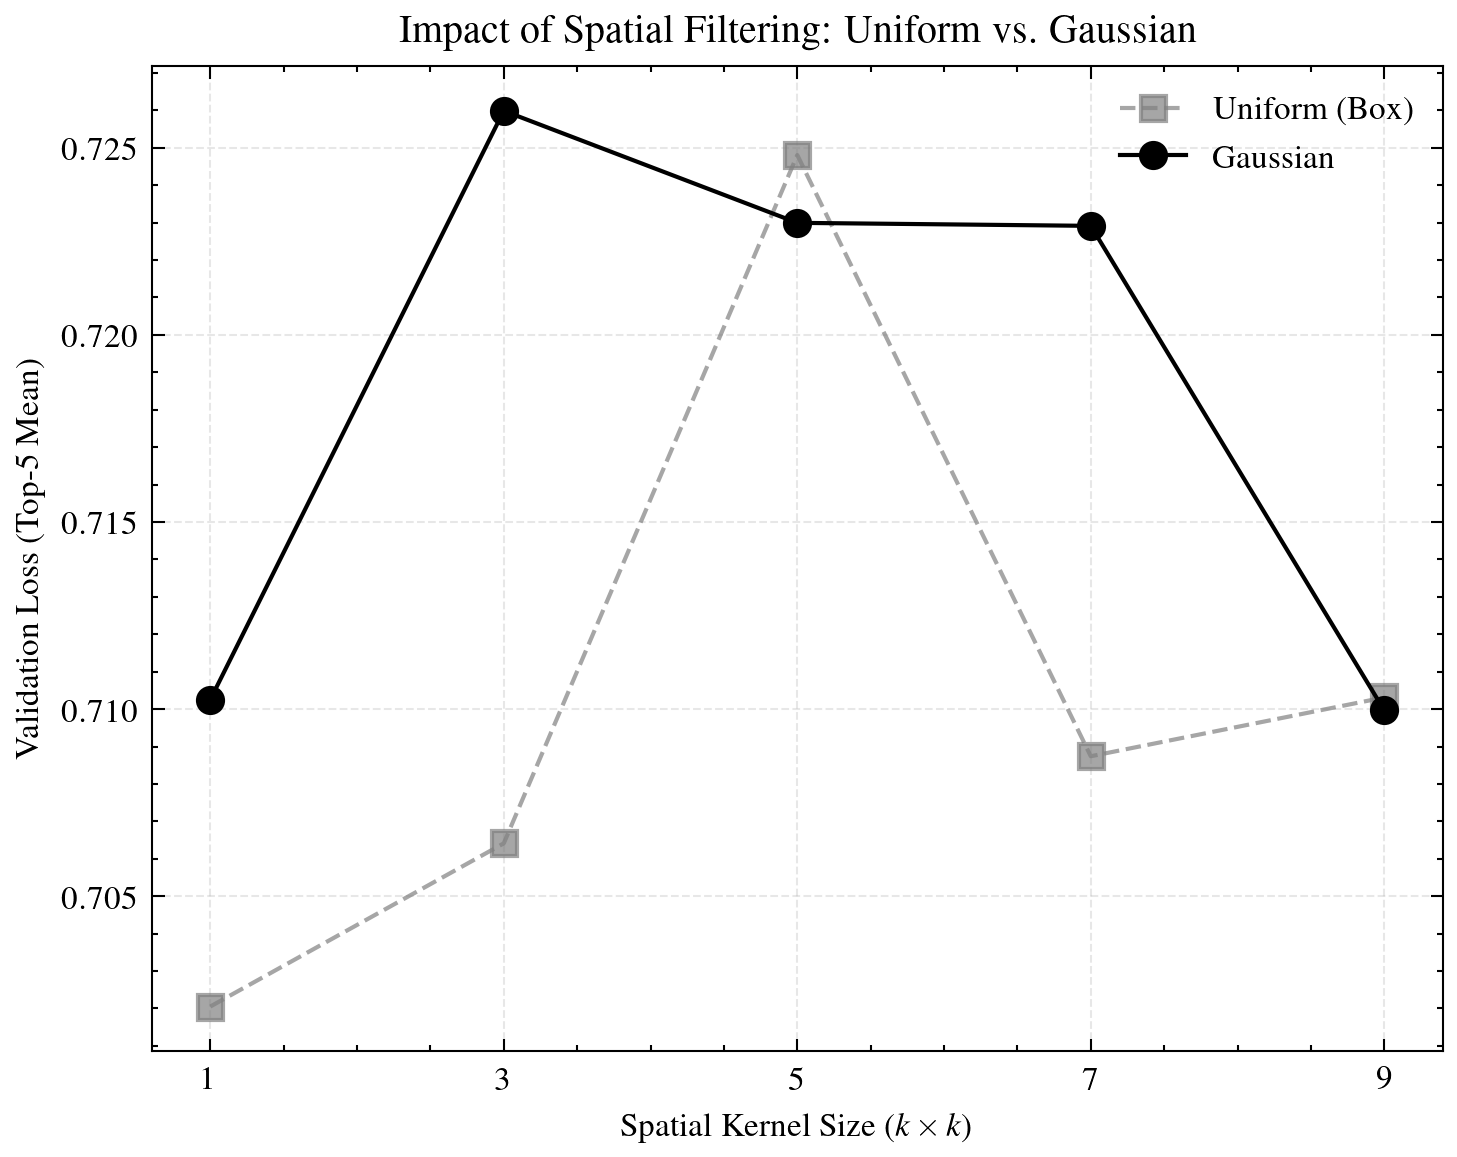

In [20]:
plt.style.use(['science', 'ieee'])
fig, ax = plt.subplots(figsize=(5, 4), dpi=300)

# Plot Uniform Kernel
"""
ax.errorbar(sizes, uniform_mean, yerr=uniform_std, fmt='s--', 
            color='gray', label='Uniform (Box)', 
            capsize=3, markersize=4, alpha=0.7)
"""
ax.plot(sizes, uniform_mean, 's--', color='gray', label='Uniform (Box)', alpha=0.7)

# Plot Gaussian Kernel
"""
ax.errorbar(sizes, gauss_mean, yerr=gauss_std, fmt='o-', 
            color='C0', label='Gaussian (Bio-inspired)', 
            capsize=3, markersize=4)
"""
ax.plot(sizes, gauss_mean, 'o-', color='C0', label='Gaussian')

# Formatting
ax.set_xlabel('Spatial Kernel Size ($k \\times k$)')
ax.set_ylabel('Validation Loss (Top-5 Mean)')
ax.set_xticks(sizes)
ax.set_title('Impact of Spatial Filtering: Uniform vs. Gaussian')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.3)

# Optional: Zoom in on the y-axis if the differences are small
# ax.set_ylim(0.69, 0.73) 

plt.tight_layout()
plt.savefig('spatial_kernel_ablation_final.png')
plt.show()

In [21]:
df = pd.read_csv(os.path.join("analysis", "kernel_sweep_train_loss.csv"))

points = ["best_k_eq_1_uniform_20260118_201435 - train_loss_epoch",
          "best_k_eq_1_gauss_20260116_074049 - train_loss_epoch",
          "best_k_eq_3_uniform_20260114_142308 - train_loss_epoch",
          "best_k_eq_3_gauss_20260114_231517 - train_loss_epoch",
          "best_k_eq_5_uniform_20260115_083650 - train_loss_epoch",
          "best_k_eq_5_gauss_20260115_175744 - train_loss_epoch",
          "best_k_eq_7_uniform_20260118_103655 - train_loss_epoch",
          "best_k_eq_7_gauss_20260118_004937 - train_loss_epoch",
          "best_k_eq_9_uniform_20260117_023810 - train_loss_epoch",
          "best_k_eq_9_gauss_20260117_151002 - train_loss_epoch"]
sizes = [1, 3, 5, 7, 9]
uniform_mean = []
uniform_std = []
gauss_mean = []
gauss_std = []
n_smallest = 5


for k in sizes:
    # dynamically find the column name for this kernel size and type
    col_u = next(p for p in points if f"k_eq_{k}_uniform" in p)
    col_g = next(p for p in points if f"k_eq_{k}_gauss" in p)
    
    # Get the top 5 smallest (best) validation losses
    # We drop NA just in case some runs were shorter
    best_5_u = df[col_u].dropna().nsmallest(n_smallest)
    best_5_g = df[col_g].dropna().nsmallest(n_smallest)
    
    # Store stats 
    uniform_mean.append(best_5_u.mean())
    uniform_std.append(best_5_u.std())  
    
    gauss_mean.append(best_5_g.mean())
    gauss_std.append(best_5_g.std())
    
    
# Print to check values
print("Kernel | Uniform Mean (Std) | Gaussian Mean (Std)")
for i, k in enumerate(sizes):
    print(f"{k}x{k}  | {uniform_mean[i]:.4f} ({uniform_std[i]:.4f}) | {gauss_mean[i]:.4f} ({gauss_std[i]:.4f})")

Kernel | Uniform Mean (Std) | Gaussian Mean (Std)
1x1  | 0.7132 (0.0028) | 0.7064 (0.0027)
3x3  | 0.7067 (0.0036) | 0.7114 (0.0045)
5x5  | 0.7118 (0.0034) | 0.7143 (0.0034)
7x7  | 0.7140 (0.0011) | 0.7117 (0.0045)
9x9  | 0.7098 (0.0011) | 0.7152 (0.0050)
